# Análise exploratória das avaliações de clientes (Olist)

Este notebook faz parte da Fase 1 do projeto. Antes de montar a base de conhecimento usada nas respostas, precisamos conhecer bem os dados: quantas avaliações existem, quantas têm comentário escrito, como são esses comentários e quais informações dos pedidos podem ajudar a filtrar as buscas.

A ideia é seguir passo a passo, olhando primeiro as tabelas originais do Kaggle e depois a base já preparada pelo script `src/data/build_documents.py`. Ao longo do caminho vamos anotando as escolhas feitas na preparação dos dados e o motivo de cada uma.

Para rodar este notebook é preciso ter os arquivos do Kaggle em `data/raw/` (instruções em `data/README.md`) e ter executado `make data` antes.

## 1. Preparando o ambiente

Começamos importando as bibliotecas e definindo a pasta raiz do projeto, para que os caminhos funcionem tanto rodando o notebook de dentro da pasta `notebooks/` quanto da raiz.

In [1]:
import sys
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data.load_olist import load_olist

pd.set_option("display.max_colwidth", 100)
IMG = ROOT / "docs" / "imagens"
print(ROOT)

/Users/coleothe/Documents/vault/1AIST/Fase 4/tech_challenge_4/submission


## 2. Carregando as tabelas originais

O dataset da Olist vem dividido em várias tabelas que se ligam por códigos (pedido, produto, cliente). Usamos seis delas. A função `load_olist` lê os arquivos e já converte as colunas de data.

In [2]:
t = load_olist(ROOT / "data" / "raw")
for nome, df in t.items():
    print(f"{nome:12s} {df.shape[0]:>7,} linhas x {df.shape[1]:>2} colunas")

reviews       99,224 linhas x  7 colunas
orders        99,441 linhas x  8 colunas
items        112,650 linhas x  7 colunas
products      32,951 linhas x  9 colunas
categorias        71 linhas x  2 colunas
customers     99,441 linhas x  5 colunas


A tabela principal para o projeto é a de avaliações (`reviews`), porque é nela que estão os comentários dos clientes. As outras servem para trazer informações complementares de cada avaliação:

- `orders`: situação do pedido, data da compra, data de entrega e data prevista de entrega;
- `items`: produtos de cada pedido, com preço e frete;
- `products` e `categorias`: categoria de cada produto, em português e em inglês;
- `customers`: estado do cliente.

As tabelas de pagamentos, vendedores e geolocalização também fazem parte do dataset, mas não foram usadas porque não ajudam a entender o conteúdo dos comentários.

## 3. Conhecendo a tabela de avaliações

Vamos olhar algumas linhas e os tipos de cada coluna.

In [3]:
reviews_raw = t["reviews"]
reviews_raw.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Pá...,2018-03-01,2018-03-02 10:26:53


In [4]:
reviews_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  str           
 4   review_comment_message   40977 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 14.2 MB


Cada linha é uma avaliação, com a nota de 1 a 5, o título e o texto do comentário, a data em que a pesquisa foi enviada ao cliente e a data em que ele respondeu. Já dá para ver que muitas linhas têm título e comentário vazios. Vamos medir isso.

In [5]:
nulos = reviews_raw.isna().mean().mul(100).round(1)
nulos.to_frame("% de valores vazios")

,% de valores vazios
review_id,0.0
order_id,0.0
review_score,0.0
review_comment_title,88.3
review_comment_message,58.7
review_creation_date,0.0
review_answer_timestamp,0.0


In [6]:
sem_nada = (reviews_raw.review_comment_title.isna() & reviews_raw.review_comment_message.isna()).mean() * 100
print(f"Avaliações sem título e sem comentário: {sem_nada:.1f}%")

Avaliações sem título e sem comentário: 57.0%


Mais da metade das avaliações (57%) não tem nenhum texto: o cliente deu só a nota. O título quase nunca é preenchido (88% vazio).

Para o projeto isso significa que a base de conhecimento vai ser bem menor do que o total de avaliações, já que só faz sentido buscar em avaliações que têm algo escrito.

## 4. Distribuição das notas

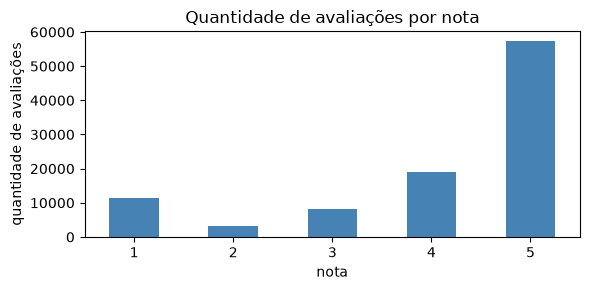

,avaliações
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [7]:
contagem_notas = reviews_raw.review_score.value_counts().sort_index()
ax = contagem_notas.plot.bar(figsize=(6, 3), rot=0, color="steelblue")
ax.set_xlabel("nota")
ax.set_ylabel("quantidade de avaliações")
ax.set_title("Quantidade de avaliações por nota")
plt.tight_layout()
plt.show()
contagem_notas.to_frame("avaliações")

A maioria dos clientes dá nota 5 (cerca de 58%). Em seguida vêm a nota 4 e a nota 1, e a nota 2 é a menos comum. Chama atenção que a nota 1 aparece mais do que as notas 2 e 3 juntas: quando o cliente fica insatisfeito, ele tende a dar a nota mínima.

## 5. Quem deixa comentário?

Uma pergunta importante é se os clientes que escrevem comentário são parecidos com os que não escrevem. Para isso calculamos, para cada nota, a porcentagem de avaliações com texto.

In [8]:
tem_texto = reviews_raw.review_comment_title.notna() | reviews_raw.review_comment_message.notna()
taxa = (
    reviews_raw.assign(tem_texto=tem_texto)
    .groupby("review_score")
    .agg(avaliacoes=("review_id", "size"), com_texto=("tem_texto", "sum"))
)
taxa["% com comentário"] = (taxa.com_texto / taxa.avaliacoes * 100).round(1)
taxa

,avaliacoes,com_texto,% com comentário
review_score,,,
1,11424,8829,77.3
2,3151,2165,68.7
3,8179,3644,44.6
4,19142,6278,32.8
5,57328,21790,38.0


O resultado mostra uma diferença grande entre as notas. Cerca de 77% dos clientes que deram nota 1 escreveram algo, contra cerca de 38% dos que deram nota 5. Ou seja, o cliente insatisfeito comenta com muito mais frequência.

Mesmo assim, a maior parte dos comentários continua vindo da nota 5, simplesmente porque existem muitos mais clientes com essa nota. O gráfico abaixo compara a distribuição das notas entre todas as avaliações e só entre as que têm comentário.

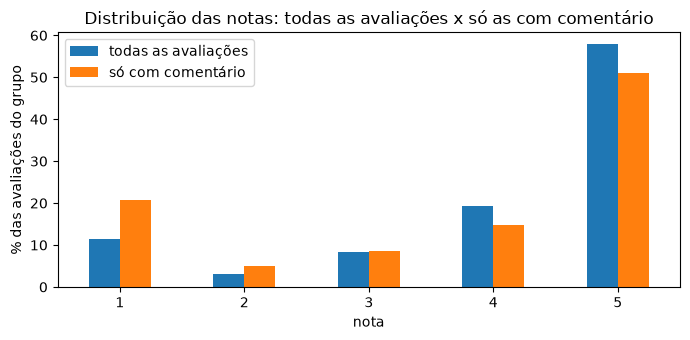

,todas as avaliações,só com comentário
review_score,,
1,11.5,20.7
2,3.2,5.1
3,8.2,8.5
4,19.3,14.7
5,57.8,51.0


In [9]:
reviews = pd.read_parquet(ROOT / "data" / "processed" / "reviews.parquet")
docs = pd.read_parquet(ROOT / "data" / "processed" / "documents.parquet")

notas = pd.DataFrame({
    "todas as avaliações": reviews.review_score.value_counts(normalize=True),
    "só com comentário": docs.review_score.value_counts(normalize=True),
}).sort_index() * 100

ax = notas.plot.bar(figsize=(7, 3.5), rot=0)
ax.set_xlabel("nota")
ax.set_ylabel("% das avaliações do grupo")
ax.set_title("Distribuição das notas: todas as avaliações x só as com comentário")
plt.tight_layout()
plt.savefig(IMG / "eda_notas_com_sem_texto.png", dpi=120)
plt.show()
notas.round(1)

Cada cor soma 100%, então a comparação é entre as duas barras da mesma nota. A nota 1 representa 11,5% de todas as avaliações, mas 20,7% das avaliações com comentário. Já as notas 4 e 5 perdem participação.

Isso tem uma consequência prática: os comentários dão mais peso às reclamações do que o conjunto completo de clientes. Se alguém perguntar "os clientes estão satisfeitos?", a resposta não deve sair só dos comentários, e sim das notas de todas as avaliações. Por esse motivo a preparação dos dados gera dois arquivos:

- `reviews.parquet`, com todas as avaliações, usado para contagens e médias de nota;
- `documents.parquet`, só com as avaliações que têm comentário, usado nas buscas.

Vale lembrar que isso é uma observação descritiva dos dados: não estamos dizendo que a insatisfação causa o comentário, apenas que os dois aparecem juntos com mais frequência.

## 6. Como ficou a base depois da preparação

O script `build_documents.py` junta as tabelas, trata o texto e grava os arquivos em `data/processed/`. Ele também salva um resumo com a quantidade de registros em cada etapa.

In [10]:
stats = json.loads((ROOT / "data" / "processed" / "build_stats.json").read_text())
etapas = pd.Series({
    "avaliações no arquivo original": stats["avaliacoes_brutas"],
    "avaliações únicas (sem repetição de review_id)": stats["avaliacoes_unicas"],
    "com algum texto (título ou comentário)": stats["com_texto"],
    "com texto útil (entram na base de busca)": stats["documentos"],
})
etapas.to_frame("quantidade")

,quantidade
avaliações no arquivo original,99224
avaliações únicas (sem repetição de review_id),98410
com algum texto (título ou comentário),42370
com texto útil (entram na base de busca),42121


Das 99.224 avaliações originais, chegamos a 42.121 que vão para a base de busca. As seções a seguir explicam cada um desses cortes.

## 7. Avaliações repetidas

Ao cruzar avaliações e pedidos, encontramos dois casos que exigem cuidado.

In [11]:
por_review = reviews_raw.groupby("review_id").order_id.nunique()
por_pedido = reviews_raw.groupby("order_id").review_id.nunique()
print("review_id que aparece em mais de um pedido:", (por_review > 1).sum())
print("pedidos com mais de uma avaliação:        ", (por_pedido > 1).sum())

review_id que aparece em mais de um pedido: 789
pedidos com mais de uma avaliação:         547


In [12]:
exemplo = por_review[por_review > 1].index[0]
reviews_raw[reviews_raw.review_id == exemplo][["review_id", "order_id", "review_score", "review_comment_message"]]

,review_id,order_id,review_score,review_comment_message
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou...."
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou...."


No primeiro caso a mesma avaliação (mesmo `review_id`, mesmo texto) aparece ligada a mais de um pedido, provavelmente porque o cliente fez compras separadas e respondeu uma única pesquisa. Se mantivéssemos as duas linhas, o mesmo comentário seria contado duas vezes. Optamos por manter **uma linha por avaliação**, usando as informações do pedido mais recente e guardando todos os códigos de pedido na coluna `order_ids`. A coluna `multi_pedido` indica esses casos.

No segundo caso um mesmo pedido recebeu avaliações diferentes. Aqui mantivemos todas, já que são avaliações distintas.

Também existem muitos comentários com exatamente o mesmo texto:

In [13]:
docs.texto_normalizado.str.lower().value_counts().head(10).to_frame("quantidade de avaliações")

,quantidade de avaliações
texto_normalizado,
muito bom,461
bom,377
recomendo,343
ótimo,266
otimo,235
excelente,204
super recomendo,133
ok,122
boa,113


São comentários curtos e genéricos, como "muito bom" e "recomendo". Decidimos mantê-los na base, porque cada um vem de um cliente diferente e eles contam quando queremos saber o que é mais frequente. O cuidado fica para a etapa de busca: lá vamos evitar que a lista de resultados venha cheia de cópias do mesmo texto.

## 8. Tamanho dos comentários

Em muitos projetos de busca em textos, os documentos longos precisam ser divididos em pedaços menores antes de serem indexados. Para saber se isso é necessário aqui, olhamos quantas palavras tem cada comentário.

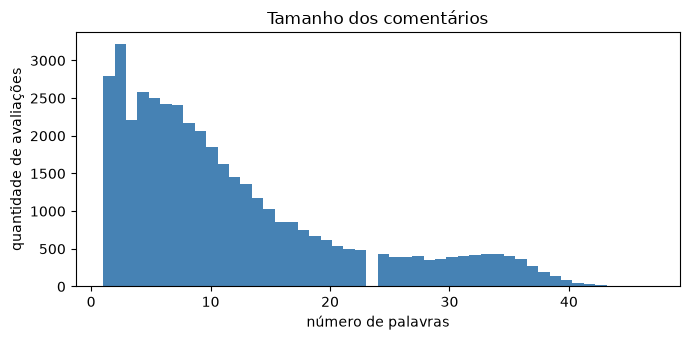

count    42121.0
mean        11.8
std          9.7
min          1.0
50%          9.0
90%         28.0
99%         38.0
max         47.0
Name: n_palavras, dtype: float64

In [14]:
ax = docs.n_palavras.plot.hist(bins=48, figsize=(7, 3.5), color="steelblue")
ax.set_xlabel("número de palavras")
ax.set_ylabel("quantidade de avaliações")
ax.set_title("Tamanho dos comentários")
plt.tight_layout()
plt.savefig(IMG / "eda_comprimento.png", dpi=120)
plt.show()
docs.n_palavras.describe(percentiles=[.5, .9, .99]).round(1)

Os comentários são curtos: metade tem até 9 palavras, 99% têm até 38 e o maior tem 47. Um texto desse tamanho cabe inteiro em uma única representação vetorial, sem perda.

Por isso decidimos **não dividir os comentários**: cada avaliação é um documento da base. Além de ser suficiente, isso mantém a reclamação e o motivo juntos (por exemplo, "chegou quebrado, a embalagem era muito fina") e facilita mostrar ao usuário qual avaliação sustenta cada resposta.

## 9. Limpeza do texto

Guardamos duas versões de cada comentário:

- `texto_original`: título e comentário juntos, exatamente como o cliente escreveu. É o texto mostrado como evidência.
- `texto_normalizado`: versão usada nas buscas, com algumas correções simples.

Veja alguns exemplos lado a lado:

In [15]:
amostra = docs[docs.texto_original.str.contains(r"\b(?:vc|tbm|n)\b|!!", case=False, regex=True)]
amostra[["texto_original", "texto_normalizado"]].head(6)

,texto_original,texto_normalizado
18,"Muito frágil !!! Achei o produto muito pequeno e onde fica a ""tela "" com os botões do microondas...","Muito frágil ! Achei o produto muito pequeno e onde fica a "" tela "" com os botões do microondas ..."
24,Muitíssimo satisfeito!!! Excelente! Recebi a encomenda bem antes do prazo. Tudo conforme o pedid...,Muitíssimo satisfeito ! Excelente ! Recebi a encomenda bem antes do prazo . Tudo conforme o pedi...
82,Entrega ok. Entregue bem antes da data!!,Entrega ok . Entregue bem antes da data !
96,EFICIENTE !!!,EFICIENTE !
97,"Produto de baixa qualidad. Produto de baixa qualidade, na foto engana bem, bota esquerdo não tem...","Produto de baixa qualidad . Produto de baixa qualidade , na foto engana bem , bota esquerdo não ..."
108,Super recomendo. Veio antes do prazo! Parabéns!!!,Super recomendo . Veio antes do prazo ! Parabéns !


Na versão normalizada separamos a pontuação das palavras, juntamos pontuações repetidas ("!!!" vira "!") e trocamos algumas abreviações comuns pela palavra inteira ("vc" por "você", "tbm" por "também", "n" por "não").

Algumas coisas foram feitas de propósito **sem** limpeza:

- os acentos foram mantidos;
- as palavras muito comuns (como "de", "o", "que") não foram retiradas;
- o "não" foi mantido em todos os casos.

O motivo é que os modelos de linguagem usados nas próximas fases entendem a frase completa, e retirar palavras pode mudar o sentido. Em "não chegou", por exemplo, tirar o "não" inverteria a reclamação.

## 10. Comentários sem conteúdo útil

In [16]:
sem_conteudo = reviews[reviews.tem_texto & ~reviews.indexavel]
print(len(sem_conteudo), "avaliações têm texto, mas sem conteúdo útil")
sem_conteudo.texto_original.value_counts().head(10).to_frame("ocorrências")

249 avaliações têm texto, mas sem conteúdo útil


,ocorrências
texto_original,
10,54
.,42
*****,12
9,10
...,9
8,8
5,8
. .,8
10. 10,6


Algumas avaliações têm só números, pontos ou uma letra ("10", "...", "A"). Um "10" é, provavelmente, o cliente repetindo a nota por escrito, informação que já está na coluna de nota. Esses 249 casos ficam fora da base de busca.

## 11. Idioma dos comentários

O modelo que vamos usar para as buscas é multilíngue, mas é bom confirmar que os comentários estão em português. Usamos a biblioteca `langdetect` em uma amostra de 2.000 comentários com pelo menos 4 palavras (em textos muito curtos a detecção não é confiável).

In [17]:
from langdetect import DetectorFactory, detect

DetectorFactory.seed = 0
amostra = docs[docs.n_palavras >= 4].sample(2000, random_state=42)

def detectar(texto):
    try:
        return detect(texto)
    except Exception:
        return "indefinido"

amostra = amostra.assign(idioma=amostra.texto_normalizado.map(detectar))
amostra.idioma.value_counts(normalize=True).mul(100).round(1).head(6).to_frame("% da amostra")

,% da amostra
idioma,
pt,95.6
it,1.9
es,1.5
de,0.2
en,0.2
sk,0.1


In [18]:
amostra[amostra.idioma != "pt"].texto_normalizado.head(8).tolist()

['Mais tarde , eu assisto esse filme . Valeu !',
 'Muito bonito . Produto bom',
 'Entrega dentro do prazo .',
 'Entrega rápida , material de ótimo acabamento .',
 'Recebi o produto certo no tempo certo',
 'Entrega no prazo , produto correto ! Recomendo',
 'Boa loja , o produto veio conforme especificado !',
 'Gosto muito de compra nas Lojas lannister .']

Cerca de 96% foram classificados como português. Olhando os demais, todos são comentários em português que a biblioteca classificou errado ("Entrega dentro do prazo." aparece como italiano, por exemplo). Concluímos que a base é toda em português e não foi preciso filtrar nada.

## 12. Dados pessoais

Antes de gravar a base, o script procura telefones, CPF, e-mails e CEPs nos comentários e troca por marcadores como `[TELEFONE]` e `[CPF]` (o código está em `src/data/pii.py`). Assim esses dados não entram na base de busca nem nas respostas.

In [19]:
pd.Series(stats["pii_mascarada"], name="ocorrências substituídas").to_frame()

,ocorrências substituídas
[CPF],1
[TELEFONE],3


In [20]:
reviews[reviews.texto_original.str.contains("[TELEFONE]", regex=False)].texto_original.tolist()

['Faltou item descrito\r\nMe ligue [TELEFONE]',
 'Aguardo o recebimento da minha encomenda com urgência...\r\nNo momento estou Insatisfeita com a empresa.\r\n[TELEFONE]\r\n[TELEFONE]']

A base pública da Olist já é anonimizada, então quase não há dados pessoais (3 telefones e 1 CPF). Mesmo assim mantivemos o tratamento, pois ele seria essencial em um uso real com dados de clientes.

## 13. Informações dos pedidos

Além do texto, cada avaliação recebeu informações do pedido: se foi entregue, quantos dias de atraso, categoria do produto, mês da compra, valor e estado do cliente. Essas informações vão servir para filtrar as buscas (por exemplo, "o que os clientes reclamam nas entregas atrasadas?"). Vamos ver se elas fazem sentido.

In [21]:
entregues = docs[docs.entregue]
por_prazo = entregues.groupby("entregue_com_atraso").review_score.agg(["count", "mean"]).round(2)
por_prazo.index = por_prazo.index.map({False: "no prazo", True: "com atraso"})
por_prazo.columns = ["avaliações", "nota média"]
por_prazo

,avaliações,nota média
entregue_com_atraso,,
no prazo,36433,4.00
com atraso,3810,1.94


As avaliações de pedidos entregues com atraso têm nota média de 1,94, contra 4,00 das entregues no prazo. A diferença é grande e indica que o atraso é um bom filtro para investigar reclamações. Novamente, isso mostra que as duas coisas andam juntas nos dados, mas não prova que o atraso é a causa da nota baixa.

In [22]:
docs.categoria_pt.value_counts().head(10).to_frame("avaliações com comentário")

,avaliações com comentário
categoria_pt,
cama_mesa_banho,4310
beleza_saude,3512
esporte_lazer,3015
informatica_acessorios,2781
moveis_decoracao,2579
relogios_presentes,2577
utilidades_domesticas,2459
telefonia,1880
automotivo,1753


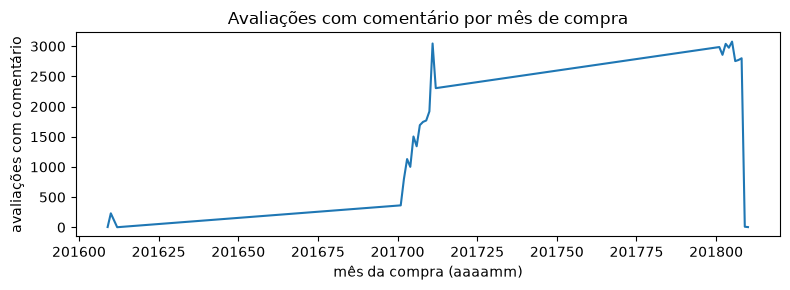

In [23]:
por_mes = docs.groupby("ano_mes_compra").size()
ax = por_mes.plot(figsize=(8, 3))
ax.set_xlabel("mês da compra (aaaamm)")
ax.set_ylabel("avaliações com comentário")
ax.set_title("Avaliações com comentário por mês de compra")
plt.tight_layout()
plt.show()

As categorias com mais comentários são cama, mesa e banho, beleza e saúde e esporte e lazer. Ao longo do tempo o volume cresce bastante a partir de 2017, acompanhando o crescimento da própria Olist, e cai no fim de 2018, onde o dataset termina.

## 14. Resumo das escolhas

| Etapa | O que foi feito | Por quê |
|---|---|---|
| Tabelas usadas | avaliações, pedidos, itens, produtos, categorias e clientes | trazem o texto e as informações para filtrar as buscas |
| Avaliações sem texto | ficam fora da base de busca, mas dentro das contagens | não há o que buscar, mas a nota continua valendo |
| Repetições | uma linha por avaliação; avaliações diferentes do mesmo pedido mantidas; textos iguais mantidos | evitar contar o mesmo comentário duas vezes sem perder clientes diferentes |
| Tamanho | cada avaliação é um documento, sem divisão | os comentários são curtos (99% com até 38 palavras) |
| Limpeza | texto original guardado; versão normalizada com pontuação separada e abreviações expandidas; acentos e "não" mantidos | não mudar o sentido do comentário |
| Sem conteúdo útil | 249 avaliações retiradas da busca | só números ou pontuação |
| Dados pessoais | telefones e CPF substituídos por marcadores | proteger dados de clientes |
| Pedidos sem entrega | marcados como não entregues, sem inventar datas | não criar informação que não existe |

Com isso a base de busca tem **42.121 avaliações**, prontas para a próxima fase, em que vamos gerar as representações vetoriais e montar o índice.